LIBRARY

In [395]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import seaborn as sns
import matplotlib.pyplot as plt

FUNCTION

In [396]:
# Fungsi untuk membersihkan data
def clean(data):
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])

    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row

    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-]', '', regex=True)
    
    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')  # Jika gagal, data menjadi NaN

    df = df.fillna(0)
    df = df.drop_duplicates(subset=["Year", "Age"]).reset_index(drop=True)
    return df

# Fungsi untuk smoothing menggunakan metode Whittaker-Henderson
def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Matriks penalti
    P = lambda_ * D.T @ D
    
    # Menyelesaikan sistem persamaan
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

DATA

In [397]:
# Membaca dan membersihkan data
italy_death = clean(pd.read_csv("Data pembanding/Italy/Italy , Deaths (period 1x1).txt", delimiter="\t"))
italy_population = clean(pd.read_csv("Data pembanding/Italy/Italy , Population size (abridged).txt", delimiter="\t"))

BACKUP

In [398]:
backup_bel_death = italy_death.copy()
backup_bel_population = italy_population.copy()

# Mengatur data agar memiliki panjang yang sama
selisih = len(italy_population) - len(italy_death)
backup_bel_population = backup_bel_population[:-selisih].reset_index(drop=True)

backup_bel_death = backup_bel_death[backup_bel_death["Age"] < 104].reset_index(drop=True)
backup_bel_population = backup_bel_population[backup_bel_population["Age"] < 104].reset_index(drop=True)


FEMALE

WHITE TAKER

In [399]:
# Menghitung qx untuk perempuan
qx_female = (backup_bel_death["Female"] / backup_bel_population["Female"]).fillna(0)

# Smoothing qx menggunakan Whittaker-Henderson
qx_head_female = qx_female.head(111)
qx_1841_female = qx_head_female[:-7]
smoothed_qx_female = whittaker_henderson(qx_1841_female, lambda_=10)
smoothed_qx_female

array([0.22823646, 0.16968367, 0.11709967, 0.07518509, 0.04480281,
       0.0247071 , 0.01262449, 0.00620222, 0.00347223, 0.00294605,
       0.00354608, 0.00457082, 0.00555839, 0.00636554, 0.00692921,
       0.00731522, 0.00761167, 0.0078952 , 0.00821041, 0.00861125,
       0.00904824, 0.00954668, 0.00997198, 0.0103259 , 0.01059356,
       0.01084018, 0.01112031, 0.01143201, 0.01174291, 0.01205788,
       0.01226627, 0.01258788, 0.01273264, 0.01276554, 0.01270178,
       0.01267871, 0.01285831, 0.01319839, 0.01353386, 0.01382121,
       0.0139419 , 0.01426751, 0.01440638, 0.01440696, 0.01423217,
       0.01412075, 0.0143386 , 0.01480123, 0.01541382, 0.01623326,
       0.01721401, 0.01876616, 0.0203057 , 0.02177548, 0.0230358 ,
       0.02444128, 0.02636284, 0.02872431, 0.03123125, 0.0339422 ,
       0.03676669, 0.04084773, 0.04491867, 0.04884328, 0.05253099,
       0.05671075, 0.06214793, 0.06819516, 0.07406671, 0.07979577,
       0.08569313, 0.09490199, 0.10521493, 0.11607408, 0.12620

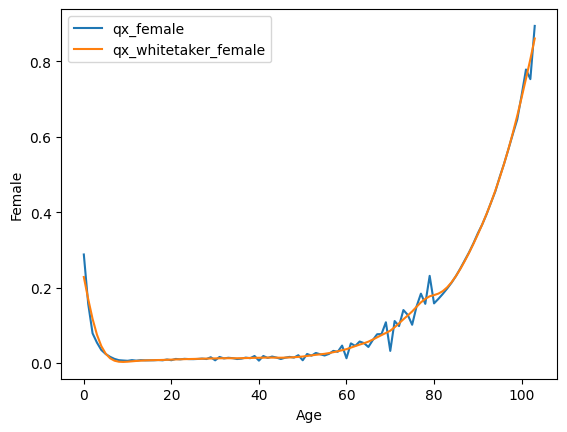

In [400]:
age = backup_bel_death["Age"].head(104)

sns.lineplot(x = age, y = qx_1841_female, label = "qx_female")
sns.lineplot(x = age, y = smoothed_qx_female, label = "qx_whitetaker_female")
plt.legend()

LAMBDA

In [453]:
dx_female = backup_bel_death["Female"]
L_female = backup_bel_population["Female"]
smoothed_double_female = np.tile(smoothed_qx_female, 150) 
t = backup_bel_death["Year"]
t0 = 1872

lambda_values = []

# Calculate lambda for each subset (assuming 104 groups based on the dataset)
for j in range(104):
    # Compute numerator for each individual lambda
    numerator_list = []
    for i in range(j, len(dx_female), 104):
        if dx_female[i] > 0 and (L_female[i] * smoothed_double_female[i]) > 0:
            log_value = np.log(dx_female[i] / (L_female[i] * smoothed_double_female[i]))
            numerator_list.append(log_value * (t.iloc[i] - t0))
        else:
            numerator_list.append(0)  # Avoid division by zero or negative values

    numerator = np.sum(numerator_list)
    denominator = np.sum((t.iloc[j::104] - t0) ** 2)  # Calculate denominator for this subset

    if denominator != 0:
        lambda_female = -numerator / denominator
    else:
        lambda_female = 0  # Set to 0 if the denominator is zero

    lambda_values.append(lambda_female)

lambda_values


[0.025628088529779856,
 0.04509446667565622,
 0.04766004301899812,
 0.04669908491375103,
 0.04416125144351945,
 0.04006872962398657,
 0.03418295096583179,
 0.028824651194767247,
 0.024152950790504377,
 0.022937599945466253,
 0.02494717377204875,
 0.0273433160525561,
 0.0285938279540875,
 0.029170199374680846,
 0.02845955210675293,
 0.027913238863083476,
 0.02737107166159002,
 0.02697019758945613,
 0.026348202160709825,
 0.02651347313157704,
 0.026587518850973053,
 0.026947893776565757,
 0.02719362738707558,
 0.02737731865738341,
 0.0272657057258386,
 0.027105849849774512,
 0.027255208216710798,
 0.027153644990809748,
 0.027073233078108116,
 0.02687068321314506,
 0.026548558950633544,
 0.026443880104794166,
 0.025912468947773222,
 0.025421027989652106,
 0.024703047032841218,
 0.024041097960146793,
 0.02355628337937924,
 0.023193908087651906,
 0.02261382676124127,
 0.022313196515165164,
 0.02147434551546724,
 0.02114403016532193,
 0.02044713866366757,
 0.01975971694027836,
 0.01888016858

ALPHA

In [454]:
# Initialize a list to store alpha values per year
alpha_list = []

# Assuming 'tahun' is an array of years relative to t0
tahun = np.arange(0, 150)

for i in range(150):  # Loop over each year
    numerator_alpha = 0
    denominator_alpha = 0
    for j in range(104):  # Loop over each age group
        dx = dx_female[j]
        Lx = L_female[j]
        qx_t0 = smoothed_qx_female[j]
        lambda_x = lambda_values[j]  # Use age-specific lambda

        if Lx * qx_t0 > 0:
            logika1 = dx / (Lx * qx_t0)
            logika2 = np.exp(-lambda_x * tahun[i])
            numerator_alpha += logika1 * logika2
            denominator_alpha += logika2 ** 2

    # Avoid division by zero
    if denominator_alpha != 0:
        alpha_t = numerator_alpha / denominator_alpha
    else:
        alpha_t = 0
        
    alpha_list.append(alpha_t)

# Convert alpha_list to a pandas Series
alpha_series = pd.Series(alpha_list, index=tahun, name='alpha')
alpha_series

0      1.042478
1      1.060977
2      1.079452
3      1.097895
4      1.116298
         ...   
145    2.467824
146    2.472888
147    2.477965
148    2.483055
149    2.488158
Name: alpha, Length: 150, dtype: float64

QX

In [455]:
# Initialize a list to store qx values
qx_female = []

for i in range(150):  # Loop over each year
    for j in range(104):  # Loop over each age group
        alpha_t = alpha_series.iloc[i]
        qx_t0 = smoothed_qx_female[j]
        lambda_x = lambda_values[j]  # Use age-specific lambda
        exponent = np.exp(-lambda_x * tahun[i])
        qx_t = alpha_t * qx_t0 * exponent
        qx_female.append(qx_t)

qx_female


[0.23793157584643035,
 0.17689155570955395,
 0.12207386868341025,
 0.078378828524126,
 0.046705960312345904,
 0.02575661210378098,
 0.013160760256211726,
 0.006465676432530879,
 0.0036197275644888056,
 0.0030711926363068253,
 0.0036967133774619214,
 0.004764982494416194,
 0.0057945009291973815,
 0.006635940847481028,
 0.007223555905039657,
 0.007625958326357695,
 0.007934997374335211,
 0.008230574062553168,
 0.00855916976217281,
 0.008977038655964425,
 0.009432593963728827,
 0.009952204647273062,
 0.010395570702388715,
 0.010764528791282722,
 0.011043552569484107,
 0.011300656941019836,
 0.01159268494909513,
 0.011917622517533599,
 0.012241730408323642,
 0.01257007957939093,
 0.012787325113593581,
 0.013122591870329454,
 0.013273497128058843,
 0.013307795123487695,
 0.01324133123359597,
 0.013217282543945736,
 0.013404508812248476,
 0.013759039952982572,
 0.014108756758648363,
 0.014408310773590722,
 0.014534128272534213,
 0.01487356574602465,
 0.015018339701061569,
 0.0150189393454117

In [457]:
ages = backup_bel_death['Age'].unique() 

# Create a DataFrame for the normalized qx values
qx_df = pd.DataFrame({
    'Age': np.repeat(ages, 150),
    'Year': np.tile(tahun + t0, len(ages)),  # Adjust years to actual years
    'qx': qx_female
})

tabel = pd.merge(backup_bel_death[['Age', 'Year']], qx_df, on=['Age', 'Year'])

pivot_table = tabel.pivot(index='Age', columns='Year', values='qx')
pivot_table

Year,1872,1873,1874,1875,1876,1877,1878,1879,1880,1881,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Age,,,,,,,,,,,,,,,,,,,,,
0,0.237932,0.176892,0.122074,0.078379,0.046706,0.025757,0.013161,0.006466,0.003620,0.003071,...,0.013325,0.013682,0.014038,0.014340,0.014478,0.014821,0.014975,0.014986,0.014818,0.014715
1,0.014951,0.015441,0.016087,0.016948,0.017979,0.019598,0.021207,0.022743,0.024065,0.025537,...,0.203032,0.214022,0.228550,0.246185,0.266444,0.288751,0.312783,0.338321,0.365205,0.393461
2,0.423545,0.455665,0.490057,0.527004,0.566683,0.608856,0.654220,0.703175,0.754640,0.808225,...,0.010604,0.010857,0.011131,0.011448,0.011763,0.012088,0.012313,0.012641,0.012814,0.012872
3,0.012845,0.012856,0.013063,0.013428,0.013801,0.014111,0.014282,0.014635,0.014819,0.014860,...,0.091130,0.100932,0.111997,0.123654,0.134663,0.146235,0.159636,0.172665,0.183203,0.191309
4,0.195650,0.200774,0.208961,0.220708,0.236055,0.254531,0.275732,0.298998,0.324135,0.350891,...,0.005329,0.006078,0.006650,0.007047,0.007360,0.007656,0.007996,0.008377,0.008798,0.009259
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.172390,0.199295,0.228759,0.258564,0.292192,0.325753,0.365896,0.411465,0.457420,0.502115,...,0.000283,0.000324,0.000364,0.000400,0.000455,0.000466,0.000484,0.000485,0.000489,0.000493
100,0.000514,0.000539,0.000541,0.000564,0.000586,0.000620,0.000660,0.000688,0.000751,0.000808,...,0.010670,0.011524,0.012830,0.014172,0.015877,0.017762,0.019602,0.021815,0.024536,0.027751
101,0.032284,0.035844,0.040749,0.045992,0.052435,0.060262,0.068485,0.078262,0.091253,0.106761,...,0.000263,0.000194,0.000168,0.000169,0.000206,0.000222,0.000247,0.000251,0.000224,0.000203


DEATH RATES

In [458]:
italy_death_rates = clean(pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/dyah_putri/Data pembanding/Italy/Italy , Death rates (period 1x1),.txt", delimiter="\t"))
italy_death_rates[["Year", "Age"]] = italy_death_rates[["Year", "Age"]].astype(int)
italy_death_rates = italy_death_rates.drop([0]).reset_index(drop=True)

# Extract 2020 and 2021 data
italy_2020 = italy_death_rates[16428:16532]
italy_2021 = italy_death_rates[16539:16643]

PERBANDINGAN TAHUN 2020

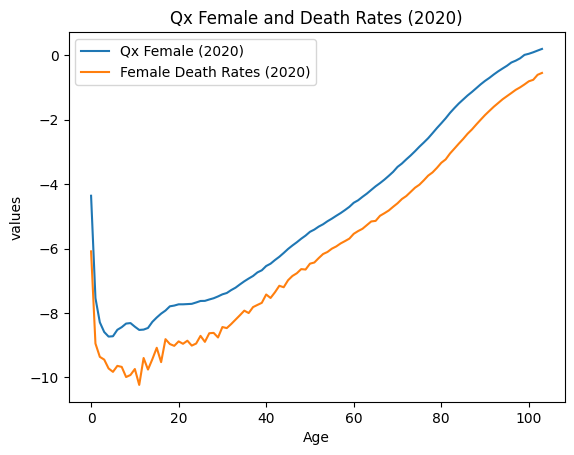

In [459]:
# Plot perbandingan qx_female_final dan death rates 2020
age = italy_2020["Age"].values
sns.lineplot(x=age, y=(np.log(qx_female[15392:15496])), label="Qx Female (2020)")
sns.lineplot(x=age, y=(np.log(italy_2020["Female"].values)), label="Female Death Rates (2020)")

plt.legend()
plt.xlabel("Age")
plt.ylabel("values")
plt.title("Qx Female and Death Rates (2020)")
plt.show()

ARIMA

Performing stepwise search to minimize aic
 ARIMA(2,2,2)(0,0,0)[0] intercept   : AIC=-727.789, Time=0.08 sec
 ARIMA(0,2,0)(0,0,0)[0] intercept   : AIC=-671.696, Time=0.01 sec
 ARIMA(1,2,0)(0,0,0)[0] intercept   : AIC=-692.235, Time=0.01 sec
 ARIMA(0,2,1)(0,0,0)[0] intercept   : AIC=-694.753, Time=0.01 sec
 ARIMA(0,2,0)(0,0,0)[0]             : AIC=-673.025, Time=0.00 sec
 ARIMA(1,2,2)(0,0,0)[0] intercept   : AIC=-649.108, Time=0.04 sec
 ARIMA(2,2,1)(0,0,0)[0] intercept   : AIC=-732.872, Time=0.03 sec
 ARIMA(1,2,1)(0,0,0)[0] intercept   : AIC=-709.652, Time=0.02 sec
 ARIMA(2,2,0)(0,0,0)[0] intercept   : AIC=-734.405, Time=0.02 sec
 ARIMA(3,2,0)(0,0,0)[0] intercept   : AIC=-733.489, Time=0.04 sec
 ARIMA(3,2,1)(0,0,0)[0] intercept   : AIC=-730.468, Time=0.09 sec
 ARIMA(2,2,0)(0,0,0)[0]             : AIC=-731.329, Time=0.01 sec

Best model:  ARIMA(2,2,0)(0,0,0)[0] intercept
Total fit time: 0.370 seconds
Best order selected by auto_arima: (2, 2, 0)


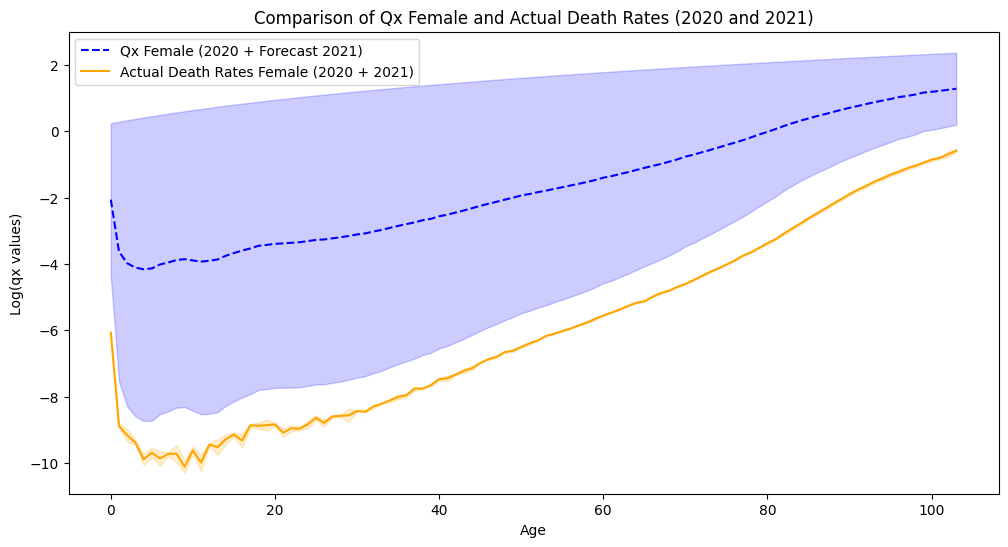

In [465]:
from pmdarima import auto_arima
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract qx_female data for 2020
qx_female_2020 = qx_female[15392:15496]

# Run auto_arima to select the best ARIMA model
auto_model = auto_arima(qx_female_2020, seasonal=False, trace=True, error_action='ignore', suppress_warnings=True)
print(f"Best order selected by auto_arima: {auto_model.order}")

# Forecast using the best ARIMA model for 104 periods (for 2021)
forecast = auto_model.predict(n_periods=104)

# Extract actual death rates for females in 2020 and 2021 from Italy dataset
italy_2020_female = italy_2020["Female"].values
italy_2021_female = italy_2021["Female"].values

# Get age values for plotting
age_2020 = italy_2020["Age"].values
age_2021 = italy_2021["Age"].values

# Concatenate data for continuous lines
age_combined = np.concatenate([age_2020, age_2021])
qx_female_combined = np.concatenate([np.log(qx_female_2020), np.log(forecast)])  # Log transformation for consistency
italy_female_combined = np.concatenate([np.log(italy_2020_female), np.log(italy_2021_female)])

# Plotting
plt.figure(figsize=(12, 6))

# Plot combined qx_female (2020 and forecasted 2021)
sns.lineplot(x=age_combined, y=qx_female_combined, label="Qx Female (2020 + Forecast 2021)", color="blue", linestyle="--")

# Plot combined actual death rates (2020 and 2021)
sns.lineplot(x=age_combined, y=italy_female_combined, label="Actual Death Rates Female (2020 + 2021)", color="orange")

# Add labels and title
plt.xlabel("Age")
plt.ylabel("Log(qx values)")
plt.title("Comparison of Qx Female and Actual Death Rates (2020 and 2021)")

# Show legend
plt.legend()
plt.show()
